### Lab Assignment - 7 
#### Image Representation, PCA, Eigenfaces and Face Recognition

##### Part A - Image Representation 

X: (400, 10304) y: (400,)
pixel range: 0.0 to 251.0
train: (320, 10304) test: (80, 10304)


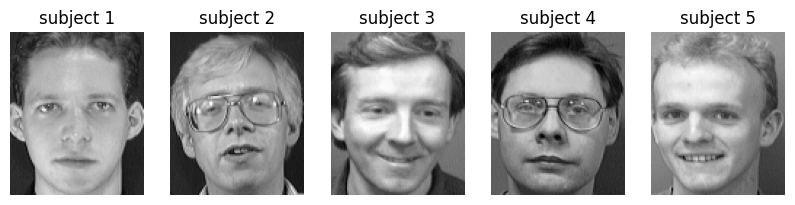

In [2]:
import numpy as np
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

DATA_DIR = Path("data")   
H, W = 112, 92

def load_orl(data_dir: Path):
    X, y = [], []
    for subj in range(1, 41):
        for img_id in range(1, 11):
            img = Image.open(data_dir / f"s{subj}" / f"{img_id}.pgm")
            arr = np.asarray(img, dtype=np.float64)       # (112, 92) pixel matrix
            X.append(arr.flatten())                        # (10304,) feature vector
            y.append(subj)
    return np.array(X), np.array(y)

X, y = load_orl(DATA_DIR)
print("X:", X.shape, "y:", y.shape)                        # expect (400, 10304) (400,)
print("pixel range:", X.min(), "to", X.max())

def stratified_split(y, n_train=8, seed=42):
    rng = np.random.default_rng(seed)
    train_idx, test_idx = [], []
    for s in np.unique(y):
        idx = rng.permutation(np.where(y == s)[0])
        train_idx += idx[:n_train].tolist()
        test_idx += idx[n_train:].tolist()
    return np.array(train_idx), np.array(test_idx)

tr, te = stratified_split(y)
X_train, y_train = X[tr], y[tr]
X_test, y_test = X[te], y[te]
print("train:", X_train.shape, "test:", X_test.shape)     # (320, 10304) (80, 10304)

# sanity: every subject appears in both sets
assert set(y_train) == set(y_test) == set(range(1, 41))

fig, ax = plt.subplots(1, 5, figsize=(10, 3))
for a, i in zip(ax, [0, 10, 20, 30, 40]):
    a.imshow(X[i].reshape(H, W), cmap="gray"); a.axis("off"); a.set_title(f"subject {y[i]}")
plt.show()

##### Part B - PCA, Eigenfaces and Compression

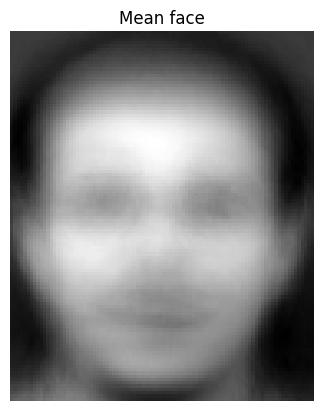

components kept (eig): 319
eigenvalues match: True
min |cos| over top 100 components: 0.9999999999999964
top 5 eigenvalues (eig): [2837009.98929293 2013339.00426591 1131088.32713936  899267.53112397
  794485.75315848]
top 5 eigenvalues (svd): [2837009.98929294 2013339.00426591 1131088.32713936  899267.53112397
  794485.75315848]


In [3]:
# --- Mean face and centering ---
mean_face = X_train.mean(axis=0)            # (10304,)
Xc = X_train - mean_face                    # (320, 10304)
n = Xc.shape[0]

plt.imshow(mean_face.reshape(H, W), cmap="gray")
plt.title("Mean face"); plt.axis("off"); plt.show()

# --- Method 1: eigendecomposition (via the small n x n matrix) ---
G = (Xc @ Xc.T) / (n - 1)                   # (320, 320)
eigvals, eigvecs = np.linalg.eigh(G)        # ascending order
order = np.argsort(eigvals)[::-1]           # sort descending
eigvals, eigvecs = eigvals[order], eigvecs[:, order]

keep = eigvals > 1e-10 * eigvals[0]         # drop the ~0 eigenvalue(s)
eigvals, eigvecs = eigvals[keep], eigvecs[:, keep]
r = len(eigvals)

comp_eig = Xc.T @ eigvecs                   # (10304, r) map back to pixel space
comp_eig /= np.linalg.norm(comp_eig, axis=0)
comp_eig = comp_eig.T                       # (r, 10304), one eigenface per row

# --- Method 2: SVD ---
U, S, Vt = np.linalg.svd(Xc, full_matrices=False)
eigvals_svd = S**2 / (n - 1)
comp_svd = Vt                               # (320, 10304)

# --- Compare the two ---
print("components kept (eig):", r)
print("eigenvalues match:", np.allclose(eigvals, eigvals_svd[:r]))
cos = np.abs(np.sum(comp_eig[:100] * comp_svd[:100], axis=1))
print("min |cos| over top 100 components:", cos.min())   # should be ~1.0
print("top 5 eigenvalues (eig):", eigvals[:5])
print("top 5 eigenvalues (svd):", eigvals_svd[:5])

k for >=90% variance: 99  (cum var = 0.9001)
  >= 80%: k = 42
  >= 95%: k = 164
  >= 99%: k = 267
compression of feature count: 10304 -> 99  (104x fewer numbers per face)


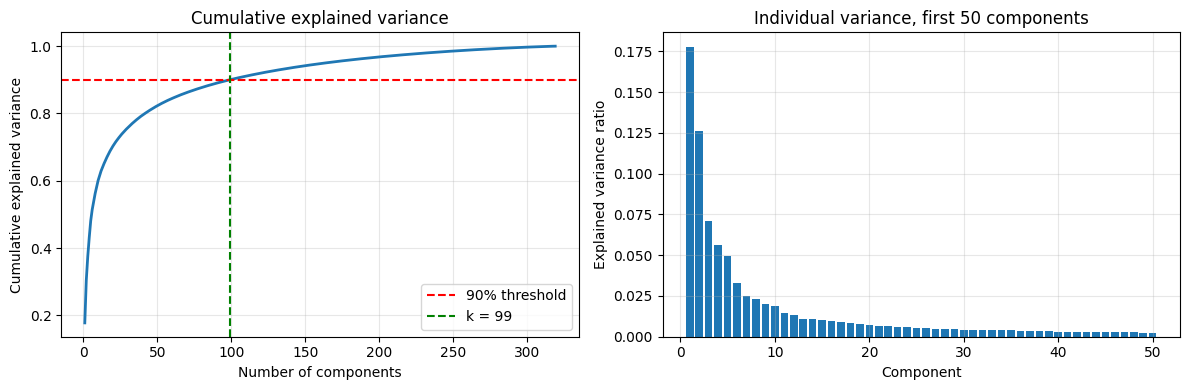

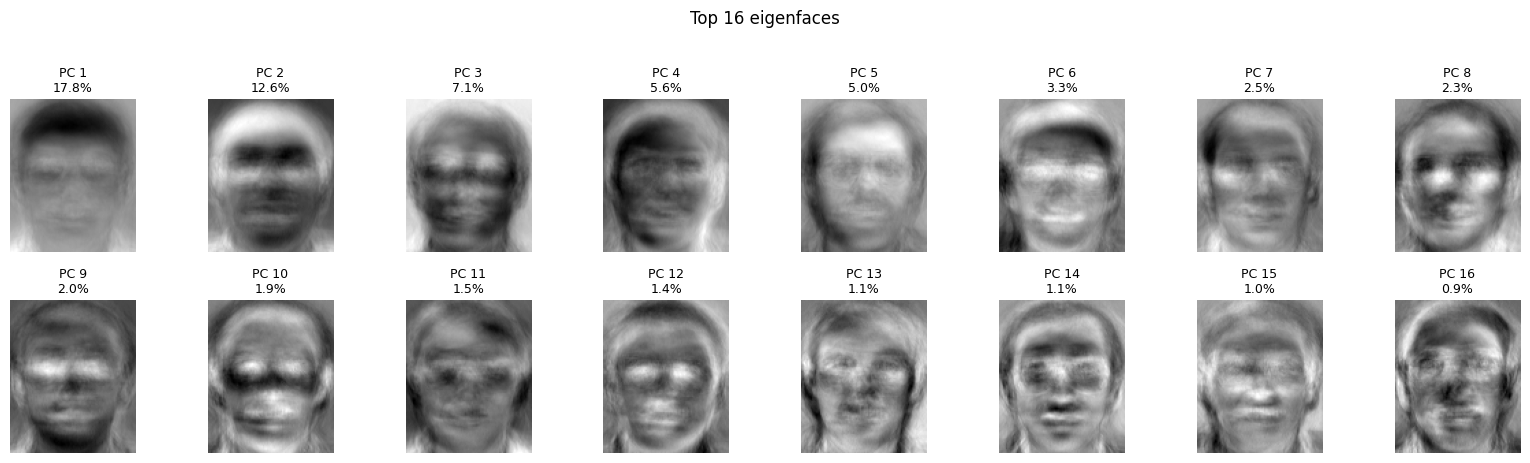

In [4]:
# --- Explained variance ---
total_var = eigvals.sum()
var_ratio = eigvals / total_var
cum_var = np.cumsum(var_ratio)

# smallest k with cumulative variance >= 90%
k90 = int(np.searchsorted(cum_var, 0.90) + 1)
print(f"k for >=90% variance: {k90}  (cum var = {cum_var[k90-1]:.4f})")
for target in (0.80, 0.95, 0.99):
    print(f"  >= {target:.0%}: k = {int(np.searchsorted(cum_var, target) + 1)}")
print(f"compression of feature count: {X_train.shape[1]} -> {k90}  "
      f"({X_train.shape[1] / k90:.0f}x fewer numbers per face)")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(range(1, len(cum_var) + 1), cum_var, lw=2)
ax[0].axhline(0.90, color="r", ls="--", label="90% threshold")
ax[0].axvline(k90, color="g", ls="--", label=f"k = {k90}")
ax[0].set_xlabel("Number of components"); ax[0].set_ylabel("Cumulative explained variance")
ax[0].set_title("Cumulative explained variance"); ax[0].legend(); ax[0].grid(alpha=0.3)

ax[1].bar(range(1, 51), var_ratio[:50])
ax[1].set_xlabel("Component"); ax[1].set_ylabel("Explained variance ratio")
ax[1].set_title("Individual variance, first 50 components"); ax[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig("explained_variance.png", dpi=150)
plt.show()

# --- Eigenfaces: first 16 ---
fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for i, a in enumerate(axes.ravel()):
    a.imshow(comp_svd[i].reshape(H, W), cmap="gray")
    a.set_title(f"PC {i+1}\n{var_ratio[i]:.1%}", fontsize=9)
    a.axis("off")
plt.suptitle("Top 16 eigenfaces", y=1.02)
plt.tight_layout()
plt.savefig("eigenfaces.png", dpi=150, bbox_inches="tight")
plt.show()

Z_train: (320, 99) Z_test: (80, 99)
train  MSE   154.13   PSNR 26.25 dB
test   MSE   323.21   PSNR 23.04 dB
train error per image: empirical 1588148.4 vs theory 1588148.4


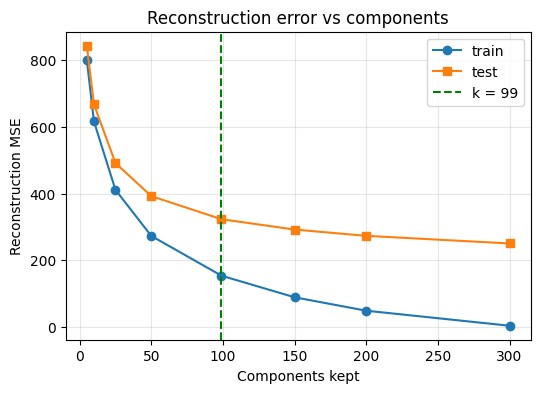

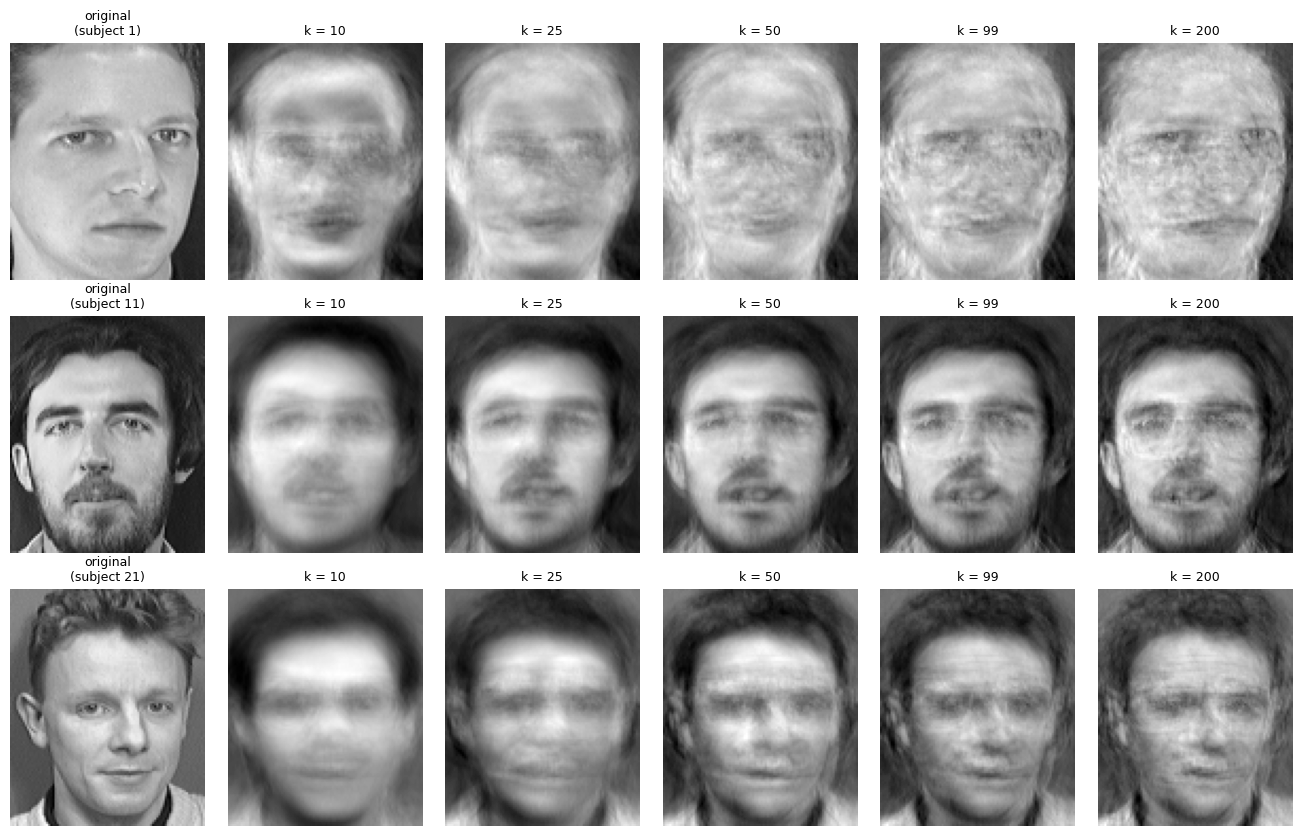

per face:  original 10304 bytes (uint8) | PCA code 792 bytes
train set: original 3.30 MB (uint8), 26.38 MB (float64)
           PCA codes 253.4 KB, plus model 8.24 MB
           codes + model 8.50 MB


In [5]:
H, W = 112, 92                                     # restore the image size (W was overwritten)

k = k90
P = comp_svd[:k]                                   # (k, 10304) principal directions

Z_train = Xc @ P.T                                 # (320, k)
Z_test = (X_test - mean_face) @ P.T                # (80, k), uses the TRAINING mean
print("Z_train:", Z_train.shape, "Z_test:", Z_test.shape)

np.savez_compressed("pca_model.npz", mean=mean_face, W=P, Z_train=Z_train, y_train=y_train)

# --- Reconstruction ---
def reconstruct(Z, W, mean):
    return Z @ W + mean

def mse(a, b):
    return np.mean((a - b) ** 2)

def psnr(a, b):
    return 10 * np.log10(255.0**2 / mse(a, b))

R_train = reconstruct(Z_train, P, mean_face)
R_test = reconstruct(Z_test, P, mean_face)
print(f"train  MSE {mse(X_train, R_train):8.2f}   PSNR {psnr(X_train, R_train):.2f} dB")
print(f"test   MSE {mse(X_test, R_test):8.2f}   PSNR {psnr(X_test, R_test):.2f} dB")

# sanity check against theory: summed squared error per image = discarded eigenvalues * (n-1)/n
emp = np.mean(np.sum((X_train - R_train) ** 2, axis=1))
theory = eigvals[k:].sum() * (n - 1) / n
print(f"train error per image: empirical {emp:.1f} vs theory {theory:.1f}")

# --- Reconstruction vs number of components ---
ks = [5, 10, 25, 50, 99, 150, 200, 300]
errs_tr, errs_te = [], []
for kk in ks:
    Wk = comp_svd[:kk]
    errs_tr.append(mse(X_train, (Xc @ Wk.T) @ Wk + mean_face))
    errs_te.append(mse(X_test, ((X_test - mean_face) @ Wk.T) @ Wk + mean_face))

plt.figure(figsize=(6, 4))
plt.plot(ks, errs_tr, "o-", label="train")
plt.plot(ks, errs_te, "s-", label="test")
plt.axvline(k90, color="g", ls="--", label=f"k = {k90}")
plt.xlabel("Components kept"); plt.ylabel("Reconstruction MSE")
plt.title("Reconstruction error vs components"); plt.legend(); plt.grid(alpha=0.3)
plt.savefig("reconstruction_error.png", dpi=150, bbox_inches="tight")
plt.show()

# --- Visual comparison on a few TEST faces ---
show_ks = [10, 25, 50, k90, 200]
rows = [0, 20, 40]                                  # test-set indices
fig, axes = plt.subplots(len(rows), len(show_ks) + 1, figsize=(2.2 * (len(show_ks) + 1), 2.8 * len(rows)))
for r_i, idx in enumerate(rows):
    axes[r_i, 0].imshow(X_test[idx].reshape(H, W), cmap="gray")
    axes[r_i, 0].set_title(f"original\n(subject {y_test[idx]})", fontsize=9)
    for c_i, kk in enumerate(show_ks, start=1):
        Wk = comp_svd[:kk]
        rec = ((X_test[idx] - mean_face) @ Wk.T) @ Wk + mean_face
        axes[r_i, c_i].imshow(np.clip(rec, 0, 255).reshape(H, W), cmap="gray")
        axes[r_i, c_i].set_title(f"k = {kk}", fontsize=9)
for a in axes.ravel():
    a.axis("off")
plt.tight_layout()
plt.savefig("reconstructions.png", dpi=150, bbox_inches="tight")
plt.show()

# --- Storage comparison ---
d = X_train.shape[1]
orig_uint8 = n * d * 1                              # as stored on disk (8-bit)
orig_f64 = n * d * 8                                # as loaded in memory
pca_codes = n * k * 8                               # reduced representation, float64
pca_model = (k * d + d) * 8                         # eigenfaces + mean face
print(f"per face:  original {d} bytes (uint8) | PCA code {k * 8} bytes")
print(f"train set: original {orig_uint8/1e6:.2f} MB (uint8), {orig_f64/1e6:.2f} MB (float64)")
print(f"           PCA codes {pca_codes/1e3:.1f} KB, plus model {pca_model/1e6:.2f} MB")
print(f"           codes + model {(pca_codes + pca_model)/1e6:.2f} MB")

##### Part C - Recognition in PCA Space 

raw pixels (10304 dims): accuracy 0.9875  (79/80)
PCA k=99 (99 dims):      accuracy 0.9875  (79/80)
k=319 predictions identical to raw: True


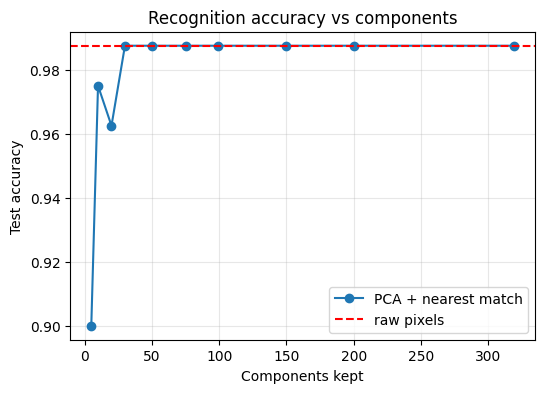

{5: 0.9, 10: 0.975, 20: 0.9625, 30: 0.9875, 50: 0.9875, 75: 0.9875, 99: 0.9875, 150: 0.9875, 200: 0.9875, 319: 0.9875}
misclassified test indices: [62] -> (true, predicted): [(32, 2)]


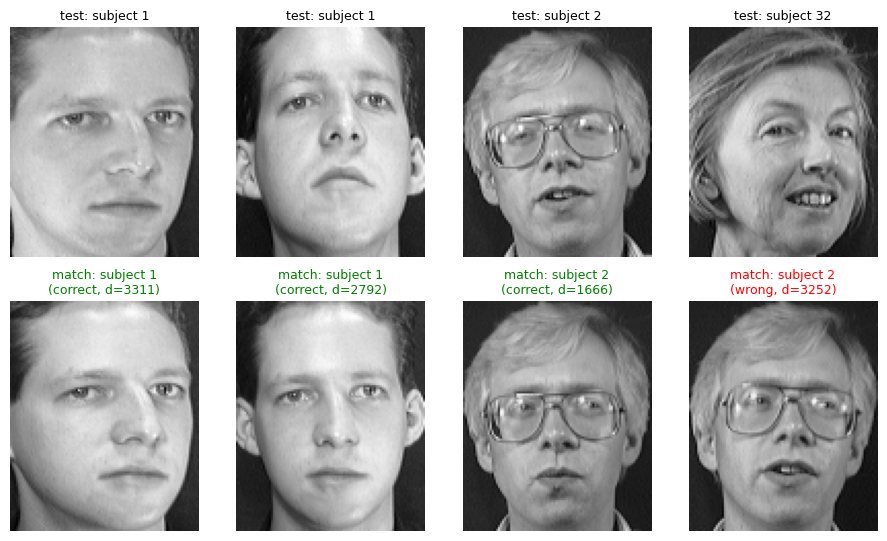

In [6]:
def nearest_neighbor(train, test):
    # squared Euclidean distances via ||a||^2 + ||b||^2 - 2ab
    d2 = (test**2).sum(1)[:, None] + (train**2).sum(1)[None, :] - 2 * test @ train.T
    d2 = np.maximum(d2, 0)
    nn = d2.argmin(axis=1)
    return nn, np.sqrt(d2[np.arange(len(test)), nn])

# --- Raw pixels vs PCA (k = 99) ---
nn_raw, dist_raw = nearest_neighbor(X_train, X_test)
nn_pca, dist_pca = nearest_neighbor(Z_train, Z_test)
acc_raw = np.mean(y_train[nn_raw] == y_test)
acc_pca = np.mean(y_train[nn_pca] == y_test)
print(f"raw pixels (10304 dims): accuracy {acc_raw:.4f}  ({int(acc_raw*80)}/80)")
print(f"PCA k={k} ({k} dims):      accuracy {acc_pca:.4f}  ({int(acc_pca*80)}/80)")

# --- Sanity check: full PCA (319 comps) must equal raw pixels ---
P_full = comp_svd[:319]
nn_full, _ = nearest_neighbor(Xc @ P_full.T, (X_test - mean_face) @ P_full.T)
print("k=319 predictions identical to raw:", np.array_equal(nn_full, nn_raw))

# --- Accuracy vs number of components ---
ks = [5, 10, 20, 30, 50, 75, 99, 150, 200, 319]
accs = []
for kk in ks:
    Pk = comp_svd[:kk]
    nn, _ = nearest_neighbor(Xc @ Pk.T, (X_test - mean_face) @ Pk.T)
    accs.append(np.mean(y_train[nn] == y_test))
plt.figure(figsize=(6, 4))
plt.plot(ks, accs, "o-", label="PCA + nearest match")
plt.axhline(acc_raw, color="r", ls="--", label="raw pixels")
plt.xlabel("Components kept"); plt.ylabel("Test accuracy")
plt.title("Recognition accuracy vs components"); plt.legend(); plt.grid(alpha=0.3)
plt.savefig("accuracy_vs_k.png", dpi=150, bbox_inches="tight")
plt.show()
print(dict(zip(ks, np.round(accs, 4))))

# --- Correct and incorrect matches (PCA k=99) ---
pred = y_train[nn_pca]
correct = np.where(pred == y_test)[0]
wrong = np.where(pred != y_test)[0]
print("misclassified test indices:", wrong, "-> (true, predicted):",
      [(int(y_test[i]), int(pred[i])) for i in wrong])

picks = [("correct", i) for i in correct[:3]] + [("wrong", i) for i in wrong[:3]]
fig, axes = plt.subplots(2, len(picks), figsize=(2.3 * len(picks), 5.5))
for c, (kind, i) in enumerate(picks):
    axes[0, c].imshow(X_test[i].reshape(H, W), cmap="gray")
    axes[0, c].set_title(f"test: subject {y_test[i]}", fontsize=9)
    j = nn_pca[i]
    axes[1, c].imshow(X_train[j].reshape(H, W), cmap="gray")
    axes[1, c].set_title(f"match: subject {y_train[j]}\n({kind}, d={dist_pca[i]:.0f})",
                         fontsize=9, color="green" if kind == "correct" else "red")
for a in axes.ravel():
    a.axis("off")
plt.tight_layout()
plt.savefig("matches.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
def evaluate_split(n_train, seed, ks=(20, 50, 99)):
    tr_i, te_i = stratified_split(y, n_train=n_train, seed=seed)
    Xtr, ytr, Xte, yte = X[tr_i], y[tr_i], X[te_i], y[te_i]
    mu = Xtr.mean(axis=0)
    _, _, Vt_ = np.linalg.svd(Xtr - mu, full_matrices=False)   # PCA fit on this split's train only
    out = {}
    nn, _ = nearest_neighbor(Xtr, Xte)
    out["raw"] = np.mean(ytr[nn] == yte)
    for kk in ks:
        Pk = Vt_[:kk]
        nn, _ = nearest_neighbor((Xtr - mu) @ Pk.T, (Xte - mu) @ Pk.T)
        out[f"PCA k={kk}"] = np.mean(ytr[nn] == yte)
    return out

for n_train in (5, 8):
    runs = [evaluate_split(n_train, seed) for seed in range(20)]
    print(f"\n{n_train} train / {10 - n_train} test per subject, 20 random splits")
    for key in runs[0]:
        vals = np.array([r[key] for r in runs])
        print(f"  {key:10s} mean {vals.mean():.4f}  std {vals.std():.4f}  min {vals.min():.4f}")


5 train / 5 test per subject, 20 random splits
  raw        mean 0.9387  std 0.0207  min 0.8750
  PCA k=20   mean 0.9220  std 0.0155  min 0.8700
  PCA k=50   mean 0.9367  std 0.0197  min 0.8700
  PCA k=99   mean 0.9340  std 0.0221  min 0.8600

8 train / 2 test per subject, 20 random splits
  raw        mean 0.9775  std 0.0192  min 0.9375
  PCA k=20   mean 0.9756  std 0.0183  min 0.9250
  PCA k=50   mean 0.9800  std 0.0174  min 0.9375
  PCA k=99   mean 0.9794  std 0.0187  min 0.9375


##### Part D - Traditional Machine Learning

     model        params  k   cv_acc
   SVM-RBF          C=10 99 0.981250
       KNN n_neighbors=1 30 0.971875
    LogReg           C=1 50 0.968750
SVM-linear         C=0.1 75 0.965625


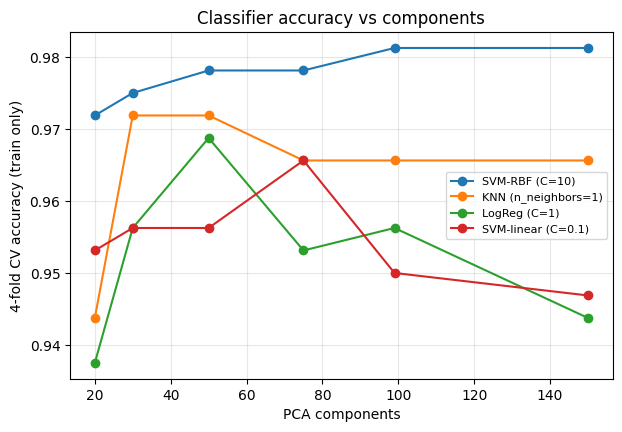

             method      settings  components  cv_acc  test_acc
            SVM-RBF          C=10          99  0.9813    0.9875
                KNN n_neighbors=1          30  0.9719    0.9875
Nearest match (PCA)     Euclidean          99     NaN    0.9875
Nearest match (raw)     Euclidean       10304     NaN    0.9875
             LogReg           C=1          50  0.9688    0.9625
         SVM-linear         C=0.1          75  0.9656    0.9500


In [8]:
import os
os.environ["LOKY_MAX_CPU_COUNT"] = "4"      # silences the joblib core-count warning (set before sklearn imports)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

K_GRID = [20, 30, 50, 75, 99, 150]

configs = {}   # (model, params) -> factory
for nn in (1, 3, 5):
    configs[("KNN", f"n_neighbors={nn}")] = lambda nn=nn: KNeighborsClassifier(n_neighbors=nn)
for C in (0.1, 1, 10):
    configs[("LogReg", f"C={C}")] = lambda C=C: make_pipeline(
        StandardScaler(), LogisticRegression(C=C, max_iter=3000))
for C in (0.01, 0.1, 1):
    configs[("SVM-linear", f"C={C}")] = lambda C=C: make_pipeline(
        StandardScaler(), SVC(kernel="linear", C=C))
for C in (1, 10, 100):
    configs[("SVM-RBF", f"C={C}")] = lambda C=C: SVC(kernel="rbf", C=C, gamma="scale")

# --- PCA refit inside each CV fold (training data only) ---
skf = StratifiedKFold(n_splits=4, shuffle=True, random_state=42)
fold_data = []
for a, b in skf.split(X_train, y_train):
    mu = X_train[a].mean(axis=0)
    _, _, Vt_ = np.linalg.svd(X_train[a] - mu, full_matrices=False)
    fold_data.append((a, b, mu, Vt_))

rows = []
for (model, params), make in configs.items():
    for kk in K_GRID:
        scores = []
        for a, b, mu, Vt_ in fold_data:
            Pk = Vt_[:kk]
            clf = make().fit((X_train[a] - mu) @ Pk.T, y_train[a])
            scores.append(clf.score((X_train[b] - mu) @ Pk.T, y_train[b]))
        rows.append(dict(model=model, params=params, k=kk, cv_acc=np.mean(scores)))
cv = pd.DataFrame(rows)

# best setting per model; ties go to the smaller (more compact) k
best = (cv.sort_values(["cv_acc", "k"], ascending=[False, True])
          .groupby("model").head(1).reset_index(drop=True))
print(best.to_string(index=False))

# CV accuracy vs k for each model's best parameters
plt.figure(figsize=(7, 4.5))
for _, r in best.iterrows():
    sub = cv[(cv.model == r.model) & (cv.params == r.params)]
    plt.plot(sub.k, sub.cv_acc, "o-", label=f"{r.model} ({r.params})")
plt.xlabel("PCA components"); plt.ylabel("4-fold CV accuracy (train only)")
plt.title("Classifier accuracy vs components"); plt.legend(fontsize=8); plt.grid(alpha=0.3)
plt.savefig("ml_cv_vs_k.png", dpi=150, bbox_inches="tight")
plt.show()

# --- Final evaluation on the held-out test set (used once) ---
final = []
for _, r in best.iterrows():
    kk = int(r.k)
    Pk = comp_svd[:kk]
    Ztr, Zte = Xc @ Pk.T, (X_test - mean_face) @ Pk.T
    clf = configs[(r.model, r.params)]().fit(Ztr, y_train)
    final.append(dict(method=r.model, settings=r.params, components=kk,
                      cv_acc=round(r.cv_acc, 4), test_acc=round(clf.score(Zte, y_test), 4)))

# similarity baselines from Part C
final.append(dict(method="Nearest match (PCA)", settings="Euclidean", components=99,
                  cv_acc=np.nan, test_acc=round(acc_pca, 4)))
final.append(dict(method="Nearest match (raw)", settings="Euclidean", components=10304,
                  cv_acc=np.nan, test_acc=round(acc_raw, 4)))

results = pd.DataFrame(final).sort_values("test_acc", ascending=False)
print(results.to_string(index=False))
results.to_csv("ml_comparison.csv", index=False)